# Réplica de «Estrenar casa se volvió un lujo»

Este cuaderno vuelve a calcular, desde los microdatos, las cifras de la nota que salen del SNIIV. Cada número se recalcula y se compara con el publicado para mostrar posibles diferencias sin alterar datos ni metodología.

**Cómo usarlo.** Instala las dependencias indicadas en `requirements.txt` desde la raíz del repositorio y ejecuta todas las celdas. Los CSV necesarios están incluidos en `data/raw/`; no se requiere descargar datos ni configurar servicios externos.

**Fuentes.** Los archivos de financiamientos y de oferta de vivienda provienen de los datos abiertos del [SNIIV](https://sniiv.sedatu.gob.mx/); el INPC se exportó del [Banco de Información Económica de INEGI](https://www.inegi.org.mx/app/indicadores/). La fuente y la fecha de consulta de cada conjunto se documentan en el README. El cuaderno identifica tablas por sus columnas, no solo por el nombre.

**Decisiones metodológicas que se conservan.** La clasificación se hace con la variable destino, nunca con modalidad, porque los códigos de modalidad cambian en 2026 y una celda lo demuestra. Todos los años se cortan de enero a mayo, porque 2026 solo llega hasta ahí. La oferta es un inventario al corte de cada mes, por lo que los meses no se suman.


## Paso 0. Los insumos

Los archivos fuente están guardados en `data/raw/` con los nombres publicados por SNIIV y el Banco de Información Económica de INEGI. El cuaderno exige todos los insumos que utiliza y se detiene con un error explícito si falta alguno; no descarga datos ni sustituye una serie por valores escritos a mano.


In [1]:
# Réplica de "Estrenar casa se volvió un lujo" — configuración

import os, re, glob, unicodedata
from pathlib import Path
import pandas as pd
import numpy as np

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data" / "raw").is_dir():
    REPO_ROOT = REPO_ROOT.parent
CARPETA = REPO_ROOT / "data" / "raw"

DEST_NUEVA = "2"   # adquisición de vivienda nueva
DEST_USADA = "3"   # adquisición de vivienda usada
MES_CORTE  = 5     # enero a mayo, porque 2026 sólo llega hasta ahí
ANIO_BASE  = "2020"
ANIO_FINAL = "2026"   # el año contra el que compara la nota

# Valores publicados en la nota. La última celda los compara contra lo que
# calcule este cuaderno. Si alguno no coincide, la nota o la base cambió.
EN_LA_NOTA = {
    "creditos_nueva_2020": 111265,
    "creditos_nueva_2026": 98132,
    "var_creditos":        -12.0,
    "monto_prom_2020":     745199,
    "monto_prom_2026":     1188061,
    "var_monto_nominal":   59.0,
    "alza_real":           16.0,
    "creditos_usada_2020": 60627,
    "creditos_usada_2026": 85718,
    "pct_usada_2020":      35.3,
    "pct_usada_2026":      46.6,
    "rango1_2020":         15.9,
    "rango1_2022":         17.5,
    "rango1_2026":         7.4,
    "economica_may2025":   2932,
    "economica_may2026":   2025,
    "economica_sem_2025":  2708,
    "economica_sem_2026":  2127,
    "var_economica_sem":   -21.0,
    "oferta_total_may2026": 377480,
}

def titulo(x):
    print("\n" + "=" * 74 + "\n" + x + "\n" + "=" * 74)

def di(etiqueta, valor, nota=None):
    linea = f"  {etiqueta:<50} {valor}"
    if nota is not None:
        linea += f"   [nota: {nota}]"
    print(linea)

print("Listo. Carpeta de datos: data/raw")


Listo. Carpeta de datos: data/raw


In [2]:
# Comprueba los insumos versionados antes de comenzar los cálculos.
ARCHIVOS_REQUERIDOS = ['financiamientos_2020.csv', 'financiamientos_2021.csv', 'financiamientos_2022.csv', 'financiamientos_2023.csv', 'financiamientos_2024.csv', 'financiamientos_2025.csv', 'Financiamientos_2026.csv', 'inpc.csv', 'oferta_viv_2020.csv', 'oferta_viv_2021.csv', 'oferta_viv_2022.csv', 'oferta_viv_2023.csv', 'oferta_viv_2024.csv', 'oferta_viv_2025.csv', 'Oferta_viv_2026.csv']
faltantes = [nombre for nombre in ARCHIVOS_REQUERIDOS if not (CARPETA / nombre).is_file()]
if faltantes:
    raise FileNotFoundError("Faltan archivos de datos en data/raw/: " + ", ".join(faltantes))

archivos_listos = sorted(glob.glob(os.path.join(CARPETA, "*.csv")))
print(f"\nCarpeta de datos: {CARPETA.relative_to(REPO_ROOT)}")
print(f"Archivos CSV disponibles: {len(archivos_listos)}")
for ruta in archivos_listos:
    print(f"  {os.path.basename(ruta):<42} {os.path.getsize(ruta)/1e6:8.2f} MB")



Carpeta de datos: data\raw
Archivos CSV disponibles: 15
  Financiamientos_2026.csv                       9.89 MB
  Oferta_viv_2026.csv                           13.42 MB
  financiamientos_2020.csv                      24.21 MB
  financiamientos_2021.csv                      26.63 MB
  financiamientos_2022.csv                      27.55 MB
  financiamientos_2023.csv                      25.31 MB
  financiamientos_2024.csv                      22.00 MB
  financiamientos_2025.csv                      21.87 MB
  inpc.csv                                       0.01 MB
  oferta_viv_2020.csv                            7.41 MB
  oferta_viv_2021.csv                            7.42 MB
  oferta_viv_2022.csv                            7.47 MB
  oferta_viv_2023.csv                            6.15 MB
  oferta_viv_2024.csv                            0.50 MB
  oferta_viv_2025.csv                           24.98 MB


In [3]:
# Lectura tolerante. Los archivos del SNIIV vienen en latin-1, a veces con
# comillas simples pegadas a los nombres de columna y a los valores, y el año
# aparece como "año", "a?o" o "anio" según el archivo.

def normaliza(nombre):
    nombre = str(nombre).strip().strip("'").strip('"')
    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = "".join(c for c in nombre if not unicodedata.combining(c))
    nombre = re.sub(r"[^A-Za-z0-9_]", "", nombre).lower()
    return {"ao": "anio", "ano": "anio", "year": "anio"}.get(nombre, nombre)

_encabezados = {}
SEPARADORES = [",", ";", "|", "\t"]

def encabezado(ruta):
    """Lee sólo la primera línea y averigua con qué codificación y con qué
    separador abre bien. Devuelve {nombre_limpio: nombre_crudo}, la
    codificación y el separador.

    Se prueban varios separadores porque un archivo con punto y coma abre sin
    marcar ningún error, sólo que con una única columna, y ahí el cuaderno
    creería que al archivo le faltan las variables cuando en realidad están.
    """
    if ruta in _encabezados:
        return _encabezados[ruta]
    mejor = None
    for enc in ("utf-8-sig", "latin-1"):
        for sep in SEPARADORES:
            try:
                d = pd.read_csv(ruta, nrows=0, encoding=enc, sep=sep,
                                engine="python")
            except Exception:
                continue
            if mejor is None or len(d.columns) > len(mejor[0]):
                mejor = (list(d.columns), enc, sep)
        if mejor and len(mejor[0]) > 1:
            break
    if mejor is None:
        raise ValueError("no se pudo leer el encabezado")
    columnas, enc, sep = mejor
    _encabezados[ruta] = ({normaliza(c): c for c in columnas}, enc, sep)
    return _encabezados[ruta]

def lee(ruta, columnas=None):
    """Lee el archivo. Si se piden columnas, sólo carga esas, que es lo que
    permite trabajar con los archivos de 25 MB sin llenar la memoria."""
    mapa, enc, sep = encabezado(ruta)
    crudas = [mapa[c] for c in columnas] if columnas else None
    d = pd.read_csv(ruta, dtype=str, encoding=enc, sep=sep,
                    keep_default_na=False, usecols=crudas)
    d.columns = [normaliza(c) for c in d.columns]
    for c in d.columns:
        d[c] = d[c].str.strip().str.strip("'").str.strip('"')
    return d[list(columnas)] if columnas else d

def num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False), errors="coerce")

def tablas():
    """Recorre los CSV de la carpeta y entrega la ruta y sus columnas limpias.
    El INPC se salta porque no es una tabla rectangular y se lee aparte."""
    for ruta in sorted(glob.glob(os.path.join(CARPETA, "*.csv"))):
        if "inpc" in os.path.basename(ruta).lower():
            continue
        try:
            mapa, _, _ = encabezado(ruta)
        except Exception:
            continue
        yield ruta, set(mapa)

# Qué columnas tiene que traer un archivo para servir a cada cosa. Así es como
# el cuaderno decide qué usar, por contenido y no por el nombre del archivo.
COLS_FIN     = {"anio", "mes", "destino", "acciones", "monto"}
COLS_INGRESO = {"anio", "mes", "destino", "acciones", "ingresos_rango"}
COLS_OFERTA  = {"anio", "mes", "viviendas"}
COLS_SEG     = ("id_segmento", "vivienda_valor")

print("CSV en la carpeta:", len(glob.glob(os.path.join(CARPETA, "*.csv"))))

CSV en la carpeta: 15


### Revisión de insumos

Esta celda corre antes de cualquier cálculo y existe por una razón concreta. Hay dos maneras de que el cuaderno entregue un número equivocado sin marcar ningún error.

La primera es un archivo de oferta al que le faltan meses. El SNIIV publica versiones distintas del mismo año y una de ellas trae únicamente el corte de mayo. Con esa versión el promedio del semestre se calcula sobre un solo mes, la comparación se vuelve mayo contra mayo y da una caída de 31% en lugar de 21%, sin que nada falle.

La segunda es un archivo de financiamientos sin la variable de ingreso, que es lo que pasa si en vez del microdato se usa el agregado por año, mes y destino. Ahí la sección 4 simplemente se queda sin esos años.

Las dos cosas se revisan abajo y se reportan por nombre de archivo.

In [4]:
titulo("0. REVISIÓN DE LOS INSUMOS")
print("Esto corre antes de cualquier cálculo. Las dos fallas que no avisan solas")
print("son un archivo de oferta al que le faltan meses y unos financiamientos sin")
print("la variable de ingreso. Las dos se detectan aquí.\n")

inv, alertas = [], []
meses_oferta, anios_ingreso = {}, set()
anios_cifras, anios_oferta = set(), set()

for ruta, cols in tablas():
    nombre = os.path.basename(ruta)
    sirve_fin = COLS_FIN <= cols
    sirve_ing = COLS_INGRESO <= cols
    seg = next((s for s in COLS_SEG if s in cols), None)
    sirve_ofe = COLS_OFERTA <= cols and seg is not None

    if sirve_fin or sirve_ing:
        familia = "financiamientos"
    elif sirve_ofe:
        familia = "oferta"
    elif "viviendas" in cols or "rezago" in cols or "con_rezago" in cols:
        familia = "rezago o déficit (no lo usa el cuaderno)"
    else:
        familia = "otro (no lo usa el cuaderno)"

    pedir = [c for c in ("anio", "mes", "ingresos_rango") if c in cols]
    try:
        d = lee(ruta, pedir) if pedir else None
    except Exception as e:
        alertas.append(f"{nombre} no se pudo leer ({e})")
        continue

    anios = sorted(d["anio"].unique()) if d is not None and "anio" in d else []
    meses = []
    if d is not None and "mes" in d:
        meses = sorted(pd.to_numeric(d["mes"], errors="coerce").dropna().astype(int).unique())

    con_ing = bool(sirve_ing and d is not None and d["ingresos_rango"].ne("").any())
    if con_ing:
        anios_ingreso |= set(anios)
    if sirve_fin:
        anios_cifras |= set(anios)
    if sirve_ofe:
        anios_oferta |= set(anios)
    if sirve_ofe and d is not None:
        m = pd.to_numeric(d["mes"], errors="coerce")
        for a in anios:
            meses_oferta.setdefault(a, set())
            meses_oferta[a] |= set(m[d["anio"] == a].dropna().astype(int))

    inv.append({
        "archivo": nombre, "familia": familia,
        "anios": ",".join(anios[:8]),
        "meses": f"{min(meses)}-{max(meses)} ({len(meses)})" if meses else "",
        "ingreso": "sí" if con_ing else "no",
        "sirve_para": ", ".join(filter(None, [
            "cifras" if sirve_fin else "", "ingreso" if sirve_ing else "",
            "oferta" if sirve_ofe else ""])) or "-",
    })

print(pd.DataFrame(inv).to_string(index=False) if inv else "No hay CSV en la carpeta.")

# Revisión 0, la más importante. La nota entera compara contra ANIO_FINAL. Si
# ese año no está, el cuaderno igual calcula todo tomando el último año que
# encuentre, y devuelve cifras correctas de un año que no es el de la nota.
for etiqueta, presentes in (("financiamientos", anios_cifras),
                            ("oferta de vivienda", anios_oferta)):
    if ANIO_FINAL not in presentes:
        tiene = ", ".join(sorted(presentes)) or "ningún año"
        alertas.append(
            f"NO HAY {etiqueta.upper()} DE {ANIO_FINAL}. Sólo hay {tiene}. "
            f"Toda la nota compara {ANIO_BASE} contra {ANIO_FINAL}, así que sin ese "
            "año no se reproduce ninguna de sus cifras. Falta subir ese archivo.")

# Revisión 1. La oferta necesita de enero a junio en 2025 y en 2026.
for anio in ("2025", "2026"):
    disponibles = meses_oferta.get(anio, set())
    if not disponibles:
        alertas.append(f"No hay oferta de {anio}.")
    elif not set(range(1, 7)) <= disponibles:
        faltan = sorted(set(range(1, 7)) - disponibles)
        alertas.append(f"A la oferta de {anio} le faltan los meses {faltan}. "
                       "Sin enero a junio completo no sale el promedio del semestre "
                       "y la comparación se vuelve mayo contra mayo, que da 31% en vez de 21%.")

# Revisión 2. Todos los años necesitan desglose por ingreso.
faltan_ing = [a for a in map(str, range(2020, 2027)) if a not in anios_ingreso]
if faltan_ing:
    alertas.append(f"Sin desglose por rango de ingreso para {', '.join(faltan_ing)}. "
                   "La sección 4 no se puede reproducir en esos años. Hace falta el "
                   "microdato completo de cada año o el archivo agregado por ingreso y mes.")

print()
if alertas:
    print("REVISAR ANTES DE SEGUIR")
    for a in alertas:
        print(" -", a)
else:
    print("Los insumos están completos.")

# Qué ve el cuaderno dentro de cada archivo. Si algo no encaja, la respuesta
# está aquí, y esto es lo que hay que copiar y pegar para pedir ayuda.
titulo("0b. COLUMNAS DETECTADAS EN CADA ARCHIVO")
print("Se necesita, para las cifras:", ", ".join(sorted(COLS_FIN)))
print("Para el ingreso:            ", ", ".join(sorted(COLS_INGRESO)))
print("Para la oferta:             ", ", ".join(sorted(COLS_OFERTA)),
      "más", " o ".join(COLS_SEG), "\n")

hay = False
for ruta in sorted(glob.glob(os.path.join(CARPETA, "*.csv"))):
    hay = True
    nombre = os.path.basename(ruta)
    if "inpc" in nombre.lower():
        print(f"{nombre}\n   (el INPC se lee aparte, no por columnas)\n")
        continue
    try:
        mapa, enc, sep = encabezado(ruta)
    except Exception as e:
        print(f"{nombre}\n   NO SE PUDO LEER EL ENCABEZADO: {e}\n")
        continue
    nombre_sep = {",": "coma", ";": "punto y coma", "|": "barra", "\t": "tabulador"}[sep]
    print(f"{nombre}   ({enc}, separado por {nombre_sep})")
    print("   ", ", ".join(sorted(mapa)) or "(sin columnas)")
    print()

if not hay:
    print("No hay ningún .csv en la carpeta.")
    otros = [os.path.basename(r) for r in glob.glob(os.path.join(CARPETA, "*"))
             if not r.endswith(".csv")][:20]
    if otros:
        print("Lo que sí hay es esto, que el cuaderno no lee:")
        for o in otros:
            print("  ", o)
        print("\nSi son .xlsx o .zip, hay que guardarlos como .csv en Drive.")


0. REVISIÓN DE LOS INSUMOS
Esto corre antes de cualquier cálculo. Las dos fallas que no avisan solas
son un archivo de oferta al que le faltan meses y unos financiamientos sin
la variable de ingreso. Las dos se detectan aquí.



                 archivo         familia anios     meses ingreso      sirve_para
Financiamientos_2026.csv financiamientos  2026   1-6 (6)      sí cifras, ingreso
     Oferta_viv_2026.csv          oferta  2026   1-6 (6)      no          oferta
financiamientos_2020.csv financiamientos  2020 1-12 (12)      sí cifras, ingreso
financiamientos_2021.csv financiamientos  2021 1-12 (12)      sí cifras, ingreso
financiamientos_2022.csv financiamientos  2022 1-12 (12)      sí cifras, ingreso
financiamientos_2023.csv financiamientos  2023 1-12 (12)      sí cifras, ingreso
financiamientos_2024.csv financiamientos  2024 1-12 (12)      sí cifras, ingreso
financiamientos_2025.csv financiamientos  2025 1-12 (12)      sí cifras, ingreso
     oferta_viv_2020.csv          oferta  2020 1-12 (12)      no          oferta
     oferta_viv_2021.csv          oferta  2021 1-12 (12)      no          oferta
     oferta_viv_2022.csv          oferta  2022 1-12 (12)      no          oferta
     oferta_viv_2023.csv    

## 1. Financiamientos

Se cargan todos los archivos de financiamientos que haya en la carpeta. Cuando un mismo año aparece en dos archivos, gana el que trae el microdato completo, porque es el único que permite abrir por ingreso y por modalidad.

La tabla de salida dice qué archivo quedó asignado a cada año. Conviene mirarla, porque si un año se está leyendo de una fuente que no esperabas, todo lo que sigue hereda ese problema.

In [5]:
titulo("1. FINANCIAMIENTOS")

# Sirven dos formatos: el microdato completo (una fila por combinación) y el
# agregado anio-mes-destino. Si los dos cubren el mismo año, gana el microdato,
# porque trae las variables de ingreso y modalidad.

COLS = ["anio", "mes", "destino", "modalidad", "ingresos_rango", "acciones", "monto"]
piezas = []

for ruta, cols in tablas():
    if not COLS_FIN <= cols:
        continue
    d = lee(ruta, [c for c in COLS if c in cols])
    for c in COLS:
        if c not in d.columns:
            d[c] = ""
    d = d[COLS]
    d["acciones"] = num(d["acciones"])
    d["monto"] = num(d["monto"])
    d["mes"] = num(d["mes"])
    # El microdato trae modalidad e ingreso. El agregado no. Cuando los dos
    # cubren el mismo año, se queda el que trae más.
    d["micro"] = int({"modalidad", "ingresos_rango"} <= cols)
    d["fuente"] = os.path.basename(ruta)
    piezas.append(d)

if not piezas:
    print("Ningún archivo de la carpeta sirve para las cifras de financiamientos.")
    print("Hace falta al menos uno con estas columnas:", ", ".join(sorted(COLS_FIN)))
    print("\nEsto es lo que falta en cada archivo que estuvo cerca:\n")
    for ruta, cols in tablas():
        faltan = COLS_FIN - cols
        if len(faltan) <= 3:
            print(f"  {os.path.basename(ruta):<36} le falta: {', '.join(sorted(faltan))}")
    print("\nSi ningún archivo aparece arriba, mira la celda 0b y copia esa salida.")
    raise SystemExit("Faltan insumos de financiamientos.")

fin = pd.concat(piezas, ignore_index=True)

# Un año, una fuente. La de mayor detalle.
prioridad = (fin.groupby(["anio", "fuente"])["micro"].max()
               .reset_index().sort_values(["anio", "micro"], ascending=[True, False])
               .drop_duplicates("anio"))
fin = fin.merge(prioridad[["anio", "fuente"]], on=["anio", "fuente"], how="inner")

print(fin.groupby("anio").agg(fuente=("fuente", "first"),
                              filas=("acciones", "size"),
                              acciones=("acciones", "sum")).to_string())


1. FINANCIAMIENTOS


                        fuente   filas   acciones
anio                                             
2020  financiamientos_2020.csv  357618   951409.0
2021  financiamientos_2021.csv  393133  1145494.0
2022  financiamientos_2022.csv  332734   833796.0
2023  financiamientos_2023.csv  306502   762818.0
2024  financiamientos_2024.csv  323908   881470.0
2025  financiamientos_2025.csv  325649   998745.0
2026  Financiamientos_2026.csv  146537   427765.0


### El control que justifica no usar la variable modalidad

Esta celda no alimenta ninguna cifra de la nota. Está aquí para dejar constancia de por qué la nota se construye sobre `destino`.

Si el monto promedio de una misma modalidad pasa de decenas de miles a más de un millón de pesos entre un año y otro, esa modalidad dejó de nombrar lo mismo. Cualquier serie construida sobre ella mezcla peras con manzanas y el salto se lee como si fuera un cambio en el mercado. La variable `destino` no tiene ese problema.

In [6]:
titulo("CONTROL. Por qué este cuaderno NO usa la variable modalidad")

ctrl = fin[fin.modalidad.isin(["2", "3"])]
if len(ctrl):
    t = (ctrl.groupby(["anio", "modalidad"])[["acciones", "monto"]].sum()
             .assign(promedio=lambda x: (x.monto / x.acciones).round())
             ["promedio"].unstack())
    print(t.to_string())
    print("\nSi el monto promedio de una modalidad salta de decenas de miles a más de")
    print("un millón, esa modalidad dejó de significar lo mismo entre un año y otro.")
    print("Por eso toda la nota se construye sobre DESTINO, que sí es estable.")
else:
    print("No hay columna modalidad en las fuentes cargadas. El control no aplica.")


CONTROL. Por qué este cuaderno NO usa la variable modalidad


modalidad          2         3
anio                          
2020         50666.0  630430.0
2021         49914.0  652324.0
2022         67731.0  747259.0
2023         73174.0  915772.0
2024         48370.0  993486.0
2025       1077089.0   20712.0
2026       1151519.0   13893.0

Si el monto promedio de una modalidad salta de decenas de miles a más de
un millón, esa modalidad dejó de significar lo mismo entre un año y otro.
Por eso toda la nota se construye sobre DESTINO, que sí es estable.


## 2. Créditos para comprar vivienda nueva, de enero a mayo

Aquí salen las dos cifras que sostienen el hallazgo. Cuántos créditos se otorgaron para comprar casa nueva en cada año y de qué tamaño fue el crédito promedio.

La ventana es enero a mayo en todos los años, sin excepción, porque 2026 todavía no tiene los demás meses. Comparar un año completo contra cinco meses infla o desinfla el resultado según convenga, y no hay forma honesta de hacerlo.

In [7]:
titulo("2. CRÉDITOS PARA COMPRAR VIVIENDA NUEVA, ENERO A MAYO DE CADA AÑO")

em = fin[fin.mes <= MES_CORTE]

def serie(destino, columna):
    x = em[em.destino == destino]
    return x.groupby("anio")[columna].sum()

nueva_acc = serie(DEST_NUEVA, "acciones")
nueva_mon = serie(DEST_NUEVA, "monto")
usada_acc = serie(DEST_USADA, "acciones")

a0 = ANIO_BASE
a1 = max(nueva_acc.index)

tabla = pd.DataFrame({
    "creditos": nueva_acc.astype(int),
    "monto_promedio": (nueva_mon / nueva_acc).round().astype(int),
})
print(tabla.to_string())

calc = {}
calc["creditos_nueva_2020"] = int(nueva_acc[a0])
calc["creditos_nueva_2026"] = int(nueva_acc[a1])
calc["var_creditos"] = round(100 * (nueva_acc[a1] / nueva_acc[a0] - 1), 1)
calc["monto_prom_2020"] = int(round(nueva_mon[a0] / nueva_acc[a0]))
calc["monto_prom_2026"] = int(round(nueva_mon[a1] / nueva_acc[a1]))
calc["var_monto_nominal"] = round(100 * ((nueva_mon[a1] / nueva_acc[a1]) /
                                         (nueva_mon[a0] / nueva_acc[a0]) - 1), 1)

di(f"Créditos vivienda nueva {a0}", f"{calc['creditos_nueva_2020']:,}", "111,265")
di(f"Créditos vivienda nueva {a1}", f"{calc['creditos_nueva_2026']:,}", "98,132")
di("Variación en el número de créditos", f"{calc['var_creditos']:+.1f}%", "-12%")
di(f"Monto promedio {a0}", f"{calc['monto_prom_2020']:,}", "745 mil")
di(f"Monto promedio {a1}", f"{calc['monto_prom_2026']:,}", "1,188,061")
di("Variación nominal del monto", f"{calc['var_monto_nominal']:+.0f}%", "59%")


2. CRÉDITOS PARA COMPRAR VIVIENDA NUEVA, ENERO A MAYO DE CADA AÑO


      creditos  monto_promedio
anio                          
2020    111265          745199
2021    115280          870105
2022    105059          997245
2023     93581         1106715
2024     95856         1084135
2025     95800         1153354
2026     98132         1188061
  Créditos vivienda nueva 2020                       111,265   [nota: 111,265]
  Créditos vivienda nueva 2026                       98,132   [nota: 98,132]
  Variación en el número de créditos                 -11.8%   [nota: -12%]
  Monto promedio 2020                                745,199   [nota: 745 mil]
  Monto promedio 2026                                1,188,061   [nota: 1,188,061]
  Variación nominal del monto                        +59%   [nota: 59%]


## 3. Vivienda usada

El mismo cálculo para el destino de vivienda usada, que es el contraste que da sentido al hallazgo. El crédito para comprar casa no desapareció, se movió.

In [8]:
titulo("3. PESO DE LA VIVIENDA USADA DENTRO DE LA COMPRA A CRÉDITO")

pct_usada = 100 * usada_acc / (usada_acc + nueva_acc)
print(pd.DataFrame({"usada": usada_acc.astype(int),
                    "nueva": nueva_acc.astype(int),
                    "pct_usada": pct_usada.round(1)}).to_string())

calc["creditos_usada_2020"] = int(usada_acc[a0])
calc["creditos_usada_2026"] = int(usada_acc[a1])
calc["pct_usada_2020"] = round(pct_usada[a0], 1)
calc["pct_usada_2026"] = round(pct_usada[a1], 1)

di(f"% usada {a0}", f"{calc['pct_usada_2020']:.1f}%", "35.3%")
di(f"% usada {a1}", f"{calc['pct_usada_2026']:.1f}%", "46.6%")
di("Crecimiento de la usada", f"{100 * (usada_acc[a1] / usada_acc[a0] - 1):+.0f}%", "41%")


3. PESO DE LA VIVIENDA USADA DENTRO DE LA COMPRA A CRÉDITO
      usada   nueva  pct_usada
anio                          
2020  60627  111265       35.3
2021  76493  115280       39.9
2022  64550  105059       38.1
2023  64293   93581       40.7
2024  82020   95856       46.1
2025  82352   95800       46.2
2026  85718   98132       46.6
  % usada 2020                                       35.3%   [nota: 35.3%]
  % usada 2026                                       46.6%   [nota: 46.6%]
  Crecimiento de la usada                            +41%   [nota: 41%]


## 4. Quién dejó de comprar casa nueva

Este es el corazón de la nota, así que vale la pena entender qué se está calculando.

El registro clasifica cada crédito en un rango de ingreso y el rango 1 es el escalón más bajo. El porcentaje se calcula sobre los créditos que sí traen dato de ingreso, no sobre el total, porque de otro modo la no respuesta se mete como si fuera un rango más.

Por eso la tabla incluye la columna `sin_dato_pct`. Si en algún año la no respuesta se dispara, el porcentaje de ese año deja de ser comparable con los demás y hay que decirlo antes de publicar.

In [9]:
titulo("4. CRÉDITOS DE VIVIENDA NUEVA POR RANGO DE INGRESO, ENERO A MAYO")
print("El rango 1 es el escalón de ingreso más bajo del registro.")
print("El porcentaje se calcula sobre los créditos CON dato de ingreso.\n")

# El desglose por ingreso puede venir en el microdato o en un archivo aparte
# de tipo anio-mes-ingresos_rango-destino. Se busca en los dos lados. Los años
# que sí traen la variable se toman completos, con blancos incluidos, porque el
# blanco es la no respuesta y hay que poder medirla.
COLS_ING = ["anio", "mes", "ingresos_rango", "acciones"]
base = em[em.destino == DEST_NUEVA]
con_variable = set(base.loc[base.ingresos_rango != "", "anio"].unique())
ing = base[base.anio.isin(con_variable)][COLS_ING].copy()

for ruta, cols in tablas():
    if not COLS_INGRESO <= cols:
        continue
    d = lee(ruta, sorted(COLS_INGRESO))
    d["acciones"] = num(d["acciones"]); d["mes"] = num(d["mes"])
    d = d[(d.mes <= MES_CORTE) & (d.destino == DEST_NUEVA) &
          (~d.anio.isin(set(ing.anio.unique())))]
    if len(d):
        ing = pd.concat([ing, d[COLS_ING]], ignore_index=True)

ing["rango"] = ing.ingresos_rango.replace("", "ND").fillna("ND")
t = ing.pivot_table(index="anio", columns="rango", values="acciones",
                    aggfunc="sum", fill_value=0)
total = t.sum(axis=1)
nd = t["ND"] if "ND" in t.columns else 0
con_dato = total - nd

res = pd.DataFrame({
    "total": total.astype(int),
    "sin_dato_pct": (100 * nd / total).round(2),
    "rango1": t["1"].astype(int),
    "rango1_pct": (100 * t["1"] / con_dato).round(1),
})
print(res.to_string())

calc["rango1_2020"] = res.loc[a0, "rango1_pct"]
calc["rango1_2022"] = res.loc["2022", "rango1_pct"]
calc["rango1_2026"] = res.loc[a1, "rango1_pct"]

di(f"Rango más bajo {a0}", f"{calc['rango1_2020']:.1f}%", "15.9%")
di("Rango más bajo 2022", f"{calc['rango1_2022']:.1f}%", "17.5%")
di(f"Rango más bajo {a1}", f"{calc['rango1_2026']:.1f}%", "7.4%")
print("\n  La columna sin_dato_pct debe quedarse baja y estable. Si en algún año se")
print("  dispara, ese año no se puede comparar con los demás.")


4. CRÉDITOS DE VIVIENDA NUEVA POR RANGO DE INGRESO, ENERO A MAYO
El rango 1 es el escalón de ingreso más bajo del registro.
El porcentaje se calcula sobre los créditos CON dato de ingreso.



       total  sin_dato_pct  rango1  rango1_pct
anio                                          
2020  111265          0.83   17537        15.9
2021  115280          0.31   19406        16.9
2022  105059          0.54   18336        17.5
2023   93581          0.19   11620        12.4
2024   95856          0.00   12628        13.2
2025   95800          0.02   11243        11.7
2026   98132          0.03    7237         7.4
  Rango más bajo 2020                                15.9%   [nota: 15.9%]
  Rango más bajo 2022                                17.5%   [nota: 17.5%]
  Rango más bajo 2026                                7.4%   [nota: 7.4%]

  La columna sin_dato_pct debe quedarse baja y estable. Si en algún año se
  dispara, ese año no se puede comparar con los demás.


## 5. Las tres series de la gráfica

El crédito promedio subió en pesos corrientes, y los pesos corrientes de 2026 no son los de 2020. Para saber si el crédito creció de verdad hay que ponerlo contra la inflación del mismo periodo, mayo contra mayo.

El archivo `data/raw/inpc.csv` contiene la exportación cruda del Banco de Información Económica de INEGI, incluidos sus encabezados. La celda toma la columna del índice general y las observaciones de mayo. Si el archivo o una observación requerida no están, la ejecución falla en lugar de sustituirlos por valores escritos a mano.


In [10]:
titulo("5. LAS TRES SERIES DE LA GRÁFICA (2020 = 100)")

# inpc.csv es la exportación cruda del Banco de Información Económica de INEGI.
ruta_inpc = CARPETA / "inpc.csv"
if not ruta_inpc.is_file():
    raise FileNotFoundError(f"No se encontró el archivo requerido: {ruta_inpc}")
crudo = ruta_inpc.read_text(encoding="latin-1").splitlines()
filas = [l for l in crudo
         if re.match(r'^"?(Ene|Feb|Mar|Abr|May|Jun|Jul|Ago|Sep|Oct|Nov|Dic) \d{4}"?,', l)]
valores = {}
for l in filas:
    p = [x.strip().strip('"') for x in l.split(",")]
    valores[p[0]] = float(p[1])
mayo = {k[-4:]: v for k, v in valores.items() if k.startswith("May")}
if a0 not in mayo or a1 not in mayo:
    raise ValueError(f"El INPC no contiene datos de mayo para {a0} y {a1}.")
idx_inpc = pd.Series({y: round(100 * v / mayo[a0], 2) for y, v in mayo.items()})
idx_inpc = idx_inpc[idx_inpc.index.isin(nueva_acc.index)].sort_index()
print(f"INPC mayo {a0} = {mayo[a0]}   INPC mayo {a1} = {mayo[a1]}")

prom = nueva_mon / nueva_acc
idx_monto = (100 * prom / prom[a0]).round(2)
idx_cred = (100 * nueva_acc / nueva_acc[a0]).round(2)

anios = sorted(set(idx_monto.index) & set(idx_inpc.index))
series = pd.DataFrame({"monto_credito": idx_monto[anios], "inflacion": idx_inpc[anios], "num_creditos": idx_cred[anios]})
print("\n" + series.to_string())

calc["alza_real"] = round(100 * (idx_monto[a1] / idx_inpc[a1] - 1), 1)
di("Alza real del crédito, descontada la inflación", f"{calc['alza_real']:+.0f}%", "16%")
print("\n  Mayo de 2023 da 120.65. Según la regla de redondeo cae en 120.6 o en 120.7.")
print("  La gráfica de la nota usa 120.7. No es un error de cálculo.")



5. LAS TRES SERIES DE LA GRÁFICA (2020 = 100)
INPC mayo 2020 = 106.162   INPC mayo 2026 = 145.527

      monto_credito  inflacion  num_creditos
2020         100.00     100.00        100.00
2021         116.76     105.89        103.61
2022         133.82     114.00         94.42
2023         148.51     120.65         84.11
2024         145.48     126.30         86.15
2025         154.77     131.89         86.10
2026         159.43     137.08         88.20
  Alza real del crédito, descontada la inflación     +16%   [nota: 16%]

  Mayo de 2023 da 120.65. Según la regla de redondeo cae en 120.6 o en 120.7.
  La gráfica de la nota usa 120.7. No es un error de cálculo.


### La gráfica

Es la misma que va en el documento, aquí en matplotlib. La del entregable es un objeto nativo de Word con sus datos editables adentro, no una imagen pegada, pero las tres series son estas.

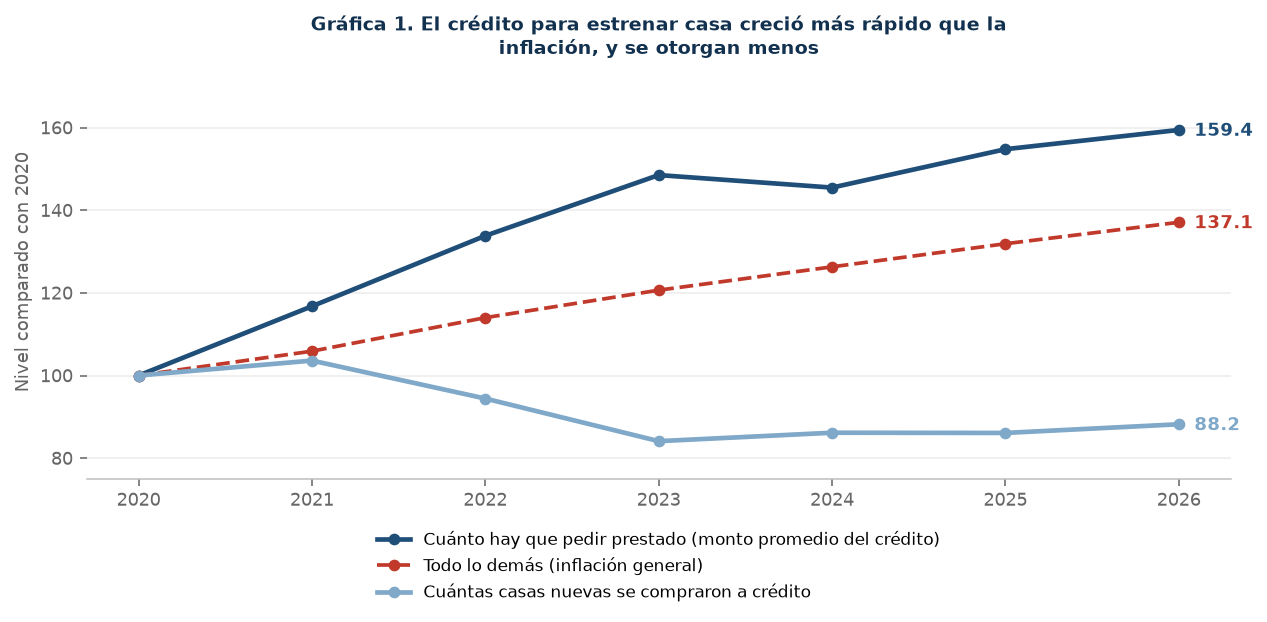

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9.2, 4.6), dpi=140)
estilos = [("monto_credito", "Cuánto hay que pedir prestado (monto promedio del crédito)", "#1F4E79", "-", 2.4),
           ("inflacion",     "Todo lo demás (inflación general)",                          "#C0392B", "--", 1.9),
           ("num_creditos",  "Cuántas casas nuevas se compraron a crédito",                "#7FA8C9", "-", 2.4)]

for col, etiqueta, color, traza, ancho in estilos:
    ax.plot(series.index, series[col], traza, color=color, linewidth=ancho,
            marker="o", markersize=5, label=etiqueta)
    ax.annotate(f"{series[col].iloc[-1]:.1f}", (len(series) - 1, series[col].iloc[-1]),
                textcoords="offset points", xytext=(8, -3), color=color,
                fontsize=9, fontweight="bold")

ax.set_ylim(75, 175); ax.set_yticks(range(80, 180, 20))
ax.set_ylabel("Nivel comparado con 2020", fontsize=9, color="#666666")
ax.grid(axis="y", color="#F0F0F0", linewidth=1)
for lado in ("top", "right", "left"):
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#BFBFBF")
ax.tick_params(colors="#666666", labelsize=9)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=1,
          frameon=False, fontsize=8.5)
ax.set_title("Gráfica 1. El crédito para estrenar casa creció más rápido que la\n"
             "inflación, y se otorgan menos",
             fontsize=10, fontweight="bold", color="#12314F", loc="center")
plt.tight_layout()
plt.show()

## 6. La oferta de vivienda registrada

Esta base es un inventario, no un flujo. Cada mes es una fotografía de cuántas viviendas están registradas en ese corte, así que sumar los meses cuenta la misma vivienda doce veces.

Hay dos problemas más que conviene tener presentes antes de leer los resultados. El primero es que la clasificación por segmento se rompe en 2024, cuando los mismos códigos dejan de nombrar los mismos rangos de precio, y la ruta alterna por UMA tampoco sirve porque esos códigos se vuelven a remapear en 2026. El segundo es que entre finales de 2025 y principios de 2026 el padrón crece de golpe por alta de desarrollos, no por obra nueva. Las celdas siguientes miden las dos cosas en lugar de suponerlas.

In [12]:
titulo("6. OFERTA DE VIVIENDA REGISTRADA (es un stock al corte del mes)")
print("Nunca se suman los meses. Cada mes es una fotografía del inventario.\n")

piezas_of = []
for ruta, cols in tablas():
    seg = next((s for s in COLS_SEG if s in cols), None)
    if not (COLS_OFERTA <= cols and seg):
        continue
    d = lee(ruta, ["anio", "mes", seg, "viviendas"])
    piezas_of.append(pd.DataFrame({
        "anio": d["anio"], "mes": num(d["mes"]), "segmento": d[seg],
        "viviendas": num(d["viviendas"]), "fuente": os.path.basename(ruta)}))

if not piezas_of:
    raise SystemExit(
        "Ningún archivo de la carpeta sirve para la oferta. Se necesita al menos\n"
        "uno con anio, mes, viviendas y una columna de segmento, que según el año\n"
        "se llama id_segmento o vivienda_valor.")

ofe = pd.concat(piezas_of, ignore_index=True)

# Un año, una fuente: la que tenga más meses, y a igualdad de meses la más
# desagregada. Esto es lo que descarta el archivo que sólo trae el corte de mayo.
mejor = (ofe.groupby(["anio", "fuente"]).agg(meses=("mes", "nunique"),
                                             filas=("viviendas", "size"))
            .reset_index()
            .sort_values(["anio", "meses", "filas"], ascending=[True, False, False])
            .drop_duplicates("anio"))
ofe = ofe.merge(mejor[["anio", "fuente"]], on=["anio", "fuente"], how="inner")

NOMBRES = {"1": "Económica", "2": "Popular", "3": "Tradicional",
           "4": "Media", "5": "Residencial", "6": "Residencial plus"}

print("Meses disponibles por año y archivo usado:")
print(ofe.groupby(["anio", "fuente"])["mes"].agg(["nunique", "min", "max"]).to_string())

print("\nADVERTENCIA. La clasificación por segmento se rompe en 2024: los mismos")
print("códigos dejan de significar lo mismo. Y en 2026 se vuelven a remapear los")
print("códigos por UMA, así que esa ruta tampoco rescata la serie. Por eso la nota")
print("sólo compara 2025 contra 2026.")
print("\nSi algún año aparece con un solo mes, es que el archivo público de ese año")
print("sólo trae ese corte. Ese año no entra en las comparaciones de mayo.")


6. OFERTA DE VIVIENDA REGISTRADA (es un stock al corte del mes)
Nunca se suman los meses. Cada mes es una fotografía del inventario.



Meses disponibles por año y archivo usado:


                          nunique  min  max
anio fuente                                
2020 oferta_viv_2020.csv       12    1   12
2021 oferta_viv_2021.csv       12    1   12
2022 oferta_viv_2022.csv       12    1   12
2023 oferta_viv_2023.csv       11    1   11
2024 oferta_viv_2024.csv        1   12   12
2025 oferta_viv_2025.csv       12    1   12
2026 Oferta_viv_2026.csv        6    1    6

ADVERTENCIA. La clasificación por segmento se rompe en 2024: los mismos
códigos dejan de significar lo mismo. Y en 2026 se vuelven a remapear los
códigos por UMA, así que esa ruta tampoco rescata la serie. Por eso la nota
sólo compara 2025 contra 2026.

Si algún año aparece con un solo mes, es que el archivo público de ese año
sólo trae ese corte. Ese año no entra en las comparaciones de mayo.


### El corte de mayo

Si un año aparece con un solo mes, es que el archivo público de ese año sólo trae ese corte. Ese año no entra en la comparación.

In [13]:
titulo("6a. CORTE DE MAYO POR SEGMENTO")

mayo_of = ofe[ofe.mes == 5]
t_mayo = mayo_of.pivot_table(index="anio", columns="segmento", values="viviendas",
                             aggfunc="sum", fill_value=0)
t_mayo.columns = [NOMBRES.get(c, c) for c in t_mayo.columns]
t_mayo["TOTAL"] = t_mayo.sum(axis=1)
print(t_mayo.to_string())

ultimo = max(t_mayo.index)
comp = pd.DataFrame({
    "viviendas": t_mayo.loc[ultimo].drop("TOTAL").astype(int),
    "pct": (100 * t_mayo.loc[ultimo].drop("TOTAL") / t_mayo.loc[ultimo, "TOTAL"]).round(1),
})
print("\nComposición de mayo de", ultimo)
print(comp.to_string())

calc["oferta_total_may2026"] = int(t_mayo.loc[ultimo, "TOTAL"])
calc["economica_may2025"] = int(t_mayo.loc["2025", "Económica"])
calc["economica_may2026"] = int(t_mayo.loc[ultimo, "Económica"])
di("Económica mayo 2025", f"{calc['economica_may2025']:,}", "2,932")
di(f"Económica mayo {ultimo}", f"{calc['economica_may2026']:,}", "2,025")
di("Total de la oferta en mayo " + ultimo, f"{calc['oferta_total_may2026']:,}", "377,480")

print("\n  CUIDADO con esta comparación mayo contra mayo. Mayo de 2025 fue el mes más")
print("  alto del año en el segmento económico, así que la caída sale inflada. La")
print("  nota compara promedios de enero a junio, que es lo que viene abajo.")


6a. CORTE DE MAYO POR SEGMENTO
      Económica  Popular  Tradicional  Media  Residencial  Residencial plus   TOTAL
anio                                                                               
2020      23934    78832        57748  31411          756                13  192694
2021      46101    77053        56382  24289          577                 6  204408
2022      65869    93965        65358  21151          406                 5  246754
2023      73959    82811        54193  14527          360                 8  225858
2025       2932    56828        90940  57925         3818                30  212473
2026       2025   211080        93530  65872         4960                13  377480

Composición de mayo de 2026
                  viviendas   pct
Económica              2025   0.5
Popular              211080  55.9
Tradicional           93530  24.8
Media                 65872  17.5
Residencial            4960   1.3
Residencial plus         13   0.0
  Económica mayo 2025        

### Por qué la nota compara semestres y no meses sueltos

Mayo de 2025 fue el mes más alto del año en el segmento económico. Comparar ese mayo contra el de 2026 da una caída de 31%, que es real pero está escogida. El promedio de enero a junio de cada año da 21% y es la cifra que va en la nota.

Este es el tipo de decisión que conviene dejar por escrito, porque alguien que rehaga el cálculo por su cuenta va a llegar al 31% y hay que poder explicarle de dónde sale la diferencia.

In [14]:
titulo("6b. ECONÓMICA MES A MES, PROMEDIO DE ENERO A JUNIO")

eco = ofe[(ofe.segmento == "1") & (ofe.mes <= 6)]
mensual = eco.pivot_table(index="mes", columns="anio", values="viviendas",
                          aggfunc="sum", fill_value=0)
print(mensual.to_string())

prom_sem = mensual.mean()
print("\nPromedio enero-junio:")
print(prom_sem.round().to_string())

if {"2025", "2026"}.issubset(prom_sem.index):
    # La variación se saca de los promedios sin redondear. Si se redondea antes,
    # el resultado se mueve de -21 a -22 sin que cambie ningún dato.
    variacion = 100 * (prom_sem["2026"] / prom_sem["2025"] - 1)
    calc["economica_sem_2025"] = int(round(prom_sem["2025"]))
    calc["economica_sem_2026"] = int(round(prom_sem["2026"]))
    calc["var_economica_sem"] = round(variacion, 2)
    di("Promedio ene-jun 2025", f"{calc['economica_sem_2025']:,}", "2,708")
    di("Promedio ene-jun 2026", f"{calc['economica_sem_2026']:,}", "2,127")
    di("Variación", f"{variacion:+.1f}%  (a unidades: {round(variacion):+.0f}%)", "-21%")


6b. ECONÓMICA MES A MES, PROMEDIO DE ENERO A JUNIO


anio   2020   2021   2022   2023  2025  2026
mes                                         
1     19600  35930  59578  70028  2396  2520
2     21271  39345  61077  70139  2444  2232
3     23104  41277  63067  70975  2714  2119
4     23423  43134  65003  71489  2915  1958
5     23934  46101  65869  73959  2932  2025
6     25672  47274  66797  75499  2848  1909

Promedio enero-junio:
anio
2020    22834.0
2021    42177.0
2022    63565.0
2023    72015.0
2025     2708.0
2026     2127.0
  Promedio ene-jun 2025                              2,708   [nota: 2,708]
  Promedio ene-jun 2026                              2,127   [nota: 2,127]
  Variación                                          -21.5%  (a unidades: -21%)   [nota: -21%]


### El salto de cobertura del registro

El desglose de abajo muestra de qué segmento viene el aumento entre mayo de 2025 y mayo de 2026. Si casi todo se concentra en uno solo, ese segmento no se puede comparar entre años, pero los demás sí.

In [15]:
titulo("6c. EL SALTO DE COBERTURA DEL REGISTRO")
print("Entre noviembre de 2025 y enero de 2026 el registro gana viviendas de golpe.")
print("Eso es alta de desarrollos en el padrón, no obra nueva. Hay que decirlo.\n")

tot_mes = ofe.groupby(["anio", "mes"])["viviendas"].sum()
print(tot_mes.tail(12).to_string())

if "2026" in ofe.anio.values and "2025" in ofe.anio.values:
    a = ofe[(ofe.anio == "2025") & (ofe.mes == 5)].groupby("segmento")["viviendas"].sum()
    b = ofe[(ofe.anio == "2026") & (ofe.mes == 5)].groupby("segmento")["viviendas"].sum()
    dif = (b - a).dropna().sort_values(ascending=False)
    dif.index = [NOMBRES.get(i, i) for i in dif.index]
    print("\nDe dónde viene el aumento entre mayo de 2025 y mayo de 2026:")
    print(dif.astype(int).to_string())
    print("\nCasi todo es un solo segmento. Ese segmento no se puede comparar entre")
    print("años. Los demás sí.")


6c. EL SALTO DE COBERTURA DEL REGISTRO
Entre noviembre de 2025 y enero de 2026 el registro gana viviendas de golpe.
Eso es alta de desarrollos en el padrón, no obra nueva. Hay que decirlo.



anio  mes
2025  7      212183
      8      211847
      9      209053
      10     225919
      11     209053
      12     268527
2026  1      322004
      2      333841
      3      349038
      4      369824
      5      377480
      6      388934



De dónde viene el aumento entre mayo de 2025 y mayo de 2026:
Popular             154252
Media                 7947
Tradicional           2590
Residencial           1142
Residencial plus       -17
Económica             -907

Casi todo es un solo segmento. Ese segmento no se puede comparar entre
años. Los demás sí.


## Verificación contra la nota publicada

La tabla compara cada cifra calculada contra lo que dice el texto. La tolerancia se saca del propio valor publicado, de modo que un número escrito sin decimales se da por bueno con media unidad de margen y uno escrito con un decimal tiene que coincidir en ese decimal.

Lo que salga marcado como REVISAR es una diferencia real que hay que resolver antes de publicar, no un detalle de redondeo.

In [16]:
titulo("VERIFICACIÓN CONTRA LA NOTA PUBLICADA")

if a1 != ANIO_FINAL:
    print(f"ALTO. El último año con datos es {a1}, no {ANIO_FINAL}.")
    print(f"Todo lo que abajo dice {ANIO_FINAL} se calculó en realidad con {a1}, así")
    print("que la comparación contra la nota no significa nada. No hay nada que")
    print(f"corregir en el texto: falta subir el archivo de {ANIO_FINAL} a la carpeta.\n")

filas = []
for clave, publicado in EN_LA_NOTA.items():
    if clave not in calc:
        filas.append((clave, publicado, "no calculado", ""))
        continue
    obtenido = calc[clave]
    # La tolerancia se saca del propio valor publicado. Si en la nota aparece
    # sin decimales, es que se redondeó a unidades y basta con media unidad.
    # Si trae un decimal, se exige ese decimal.
    tol = 0.5 if float(publicado) == int(publicado) else 0.05
    coincide = abs(float(obtenido) - float(publicado)) <= tol + 1e-9
    filas.append((clave, publicado, obtenido, "OK" if coincide else "REVISAR"))

ver = pd.DataFrame(filas, columns=["cifra", "en_la_nota", "calculado", "estado"])
print(ver.to_string(index=False))

malas = ver[ver.estado == "REVISAR"]
print()
if len(malas) == 0:
    print("Todas las cifras de microdato de la nota se reproducen con estos archivos.")
else:
    print(f"Hay {len(malas)} cifra(s) que no coinciden. Antes de publicar hay que")
    print("decidir cuál es la buena, la del cuaderno o la del texto.")


VERIFICACIÓN CONTRA LA NOTA PUBLICADA
               cifra  en_la_nota  calculado estado
 creditos_nueva_2020    111265.0  111265.00     OK
 creditos_nueva_2026     98132.0   98132.00     OK
        var_creditos       -12.0     -11.80     OK
     monto_prom_2020    745199.0  745199.00     OK
     monto_prom_2026   1188061.0 1188061.00     OK
   var_monto_nominal        59.0      59.40     OK
           alza_real        16.0      16.30     OK
 creditos_usada_2020     60627.0   60627.00     OK
 creditos_usada_2026     85718.0   85718.00     OK
      pct_usada_2020        35.3      35.30     OK
      pct_usada_2026        46.6      46.60     OK
         rango1_2020        15.9      15.90     OK
         rango1_2022        17.5      17.50     OK
         rango1_2026         7.4       7.40     OK
   economica_may2025      2932.0    2932.00     OK
   economica_may2026      2025.0    2025.00     OK
  economica_sem_2025      2708.0    2708.00     OK
  economica_sem_2026      2127.0    2127.00

## Lo que no sale de este cuaderno y hay que citar aparte

Tres cifras de la nota vienen de publicaciones, no de microdatos, así que no se replican aquí y su fuente va citada directamente en el documento.

El índice de precios de la vivienda de la Sociedad Hipotecaria Federal, que es de donde salen las variaciones de precio por segmento, se publica como boletín trimestral. El índice de precios al productor de la construcción residencial del INEGI, que es de donde sale el costo de los insumos, se difunde en los informes de la Cámara Mexicana de la Industria de la Construcción. Y las cifras de rezago y déficit habitacional las publica el propio SNIIV ya calculadas.

Una nota sobre redondeo. Los índices se imprimen con dos decimales a propósito. Mayo de 2023 da 120.65, que según la regla de redondeo que se use cae en 120.6 o en 120.7. La gráfica usa 120.7 y no es un error de cálculo.